# Executive Summary

**Question 1 — which 3 cohorts convert best, and on what metric?**
FT rate (leads reaching **First Trip**) is the north-star metric. After fixing two data-quality bugs (duplicate
leads double-counted across cohorts; 22 internally-inconsistent "FT with no logged Connect" rows), the honest
answer is: **`Single Referral > 7 days` and `Khanna- 2W 26th Jul` are statistically tied for the top cold
cohort** (~0.9% FT rate, overlapping 95% CIs, Fisher's exact p=1.0 between them). A Fisher's exact test
confirms `OLX` is a real (p<0.001) but much weaker #3. Among warm (pre-qualified) cohorts, the three
`PreOb`/`AI Connected` cohorts are directionally ranked but not statistically separable from each other.

**Question 3 — what factors influence the chance of reaching FT?**
A Logistic Regression (interpretable coefficients) cross-checked against a Random Forest (feature importances)
agree on three real factors: **`OB_after_upload`** (onboarding), **`tag_filled`** (telecaller diligence), and
**`Connected`**. The classifier itself has excellent ranking power (ROC-AUC 0.96) despite the target being
extremely rare (0.18% of leads) — calling just the **top 1% of leads by predicted probability captures 84%**
of all eventual FT conversions, which is the most actionable output of this analysis.

**Data-quality issues found and handled** (see Data Integrity section): duplicate lead attribution across
cohorts, internally-inconsistent funnel rows, a systemically broken timing field for one cohort, and severe
class imbalance in the model target — each is fixed or explicitly flagged rather than silently ignored, and
every headline number is reported with a confidence interval or p-value rather than a bare point estimate.

In [22]:
import numpy as np
import pandas as pd

In [23]:
# Load the dataset
data = pd.read_csv("Vahan_Case_Study.csv")
data.head()

,upload_date,lead_source,candidate_phone,Uploaded Leads,Attempted,Connected,Attempt per Lead,tag_filled,Interested,OB_after_upload,OB_after_first_attempt,FT_after_upload,FT_after_first_attempt,upload_to_first_attempt_P50 (hrs),Attempted %,Attempt to Connected %,Connect to Interested %,Interested to FT_after_first_attempt %,Attempted to FT_after_upload %
0,18-07-2026,2W3W - 3WAHD - Khanna - 3W - 17 Jul,91148e89d497914604c9c248ccd2aca212fac665bdc396...,1,1,1,1.0,1,0,0,0,0,0,112.0,100,100.0,0.0,NaN,0.0
1,18-07-2026,2W3W - 3WAHD - Khanna - 3W - 17 Jul,4aa4e7a4f4a3b9fa608c4c1729be6a8accc31f58b3d8b1...,1,1,0,1.0,0,0,0,0,0,0,112.0,100,0.0,NaN,NaN,0.0
2,18-07-2026,2W3W - 3WAHD - Khanna - 3W - 17 Jul,0e97e34090259c1ce6cef1fd1c491fcfc469ba9d2d1ce7...,1,1,0,1.0,0,0,0,0,0,0,89.0,100,0.0,NaN,NaN,0.0
3,18-07-2026,2W3W - 3WAHD - Khanna - 3W - 17 Jul,cdc003718802cffa769a478bcc0fe31aa20ac3ffe97a7c...,1,1,0,1.0,0,0,0,0,0,0,106.0,100,0.0,NaN,NaN,0.0
4,18-07-2026,2W3W - 3WAHD - Khanna - 3W - 17 Jul,d70833a770ab63e1992254dad148b100bbbadbe0e94673...,1,1,0,1.0,0,0,0,0,0,0,90.0,100,0.0,NaN,NaN,0.0


## Data integrity checks (before any aggregation)

Run before trusting any cohort numbers:
1. **Duplicate leads across cohorts** — does the same `candidate_phone` show up under more than one `lead_source`? If so, summing `FT_after_upload` per cohort can double-count a single converted lead.
2. **Funnel monotonicity** — flag rows where a later funnel stage is marked `1` while an earlier one is `0` (e.g. `FT_after_upload=1` but `Connected=0`), since these are internally inconsistent and may not be real conversions.

In [24]:
dupe_counts = data['candidate_phone'].value_counts()
dupe_phones = dupe_counts[dupe_counts > 1].index
dupe_rows = data[data['candidate_phone'].isin(dupe_phones)]
span = dupe_rows.groupby('candidate_phone')['lead_source'].nunique()
ft_per_phone = dupe_rows.groupby('candidate_phone')['FT_after_upload'].sum()

print(f"Repeated phone hashes: {len(dupe_phones)} ({len(dupe_rows)} rows, {len(dupe_rows)/len(data):.1%} of data)")
print(f"  -> all of them span multiple lead_source values: {(span > 1).all()}")
print(f"  -> phones double-credited with FT_after_upload=1 more than once: {(ft_per_phone > 1).sum()}")

print()
anomaly = (data['FT_after_upload'] == 1) & (data['Connected'] == 0)
print(f"FT_after_upload=1 rows with Connected=0 (internally inconsistent): {anomaly.sum()} of {data['FT_after_upload'].sum()} total FT events")
print(data.loc[anomaly, 'lead_source'].value_counts())

print()
# Fix 1: dedup to one row per lead, keeping their most-advanced funnel state,
# so a lead counted under two lead_source values can't inflate either cohort's FT count.
priority_cols = ['FT_after_upload', 'Interested', 'Connected', 'Attempted']
data_clean = (
    data.sort_values(priority_cols, ascending=False)
        .drop_duplicates(subset='candidate_phone', keep='first')
        .copy()
)
data_clean['ft_anomaly'] = (data_clean['FT_after_upload'] == 1) & (data_clean['Connected'] == 0)
print(f"Rows: {len(data)} -> {len(data_clean)} after dedup. FT_after_upload sum: {data['FT_after_upload'].sum()} -> {data_clean['FT_after_upload'].sum()}")

Repeated phone hashes: 1077 (2177 rows, 12.0% of data)
  -> all of them span multiple lead_source values: True
  -> phones double-credited with FT_after_upload=1 more than once: 1

FT_after_upload=1 rows with Connected=0 (internally inconsistent): 22 of 54 total FT events
lead_source
Khanna- 2W 26th Jul                            7
Single Referral > 7 days- 24th Jul             4
OLX - Ashwin - 2W - 17 Jul                     3
PreOb-Ob Fees Paid 29th Jul (set 1)            3
PreOb-Ob Fees Paid 29th Jul (set 2)            2
AI Connected but not Connected by TC- Set 1    2
AI Connected but not Connected by TC- Set 2    1
Name: count, dtype: int64

Rows: 18198 -> 17098 after dedup. FT_after_upload sum: 54 -> 53


## Cohort analysis: which `lead_source` cohorts convert best?

`FT` = **First Trip** (confirmed). North-star metric: `FT_after_upload` rate — leads that make it all the way
to a first trip, not intermediate funnel steps like connect/interest rate.

Built on `data_clean` (deduped leads, one row per unique `candidate_phone`) so a lead appearing under two
`lead_source` values can't inflate either cohort's count. Cohorts under `MIN_LEADS` are excluded, "warm"
cohorts (already pre-qualified — fees already paid, or AI-prescreened) are ranked separately from "cold"
acquisition cohorts, and every rate is reported with a 95% Wilson confidence interval — with FT counts this
small (single digits per cohort), point estimates alone are misleading; cohorts whose intervals overlap are
**not** reliably distinguishable from each other and shouldn't be read as a clean ranking.

In [25]:
def wilson_ci(successes, n, z=1.96):
    """95% Wilson score interval for a proportion, safe for small n / rare events."""
    if n == 0:
        return 0.0, 0.0, 0.0
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = (z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5)) / denom
    return p * 100, max(0, (center - half) * 100), (center + half) * 100

cohort = data_clean.groupby('lead_source').agg(
    leads=('Uploaded Leads', 'sum'),
    attempted=('Attempted', 'sum'),
    connected=('Connected', 'sum'),
    interested=('Interested', 'sum'),
    ft_after_upload=('FT_after_upload', 'sum'),
    ft_anomalies=('ft_anomaly', 'sum'),  # FT events with no logged Connected=1 -- data-quality flag, not dropped by default
).reset_index()

cohort['attempt_rate']  = cohort['attempted'] / cohort['leads'] * 100
cohort['connect_rate']  = cohort['connected'] / cohort['attempted'] * 100
cohort['interest_rate'] = cohort['interested'] / cohort['connected'] * 100

ci = cohort.apply(lambda r: wilson_ci(r['ft_after_upload'], r['leads']), axis=1, result_type='expand')
cohort[['ft_rate', 'ft_rate_ci_low', 'ft_rate_ci_high']] = ci

cohort.sort_values('ft_rate', ascending=False)

,lead_source,leads,attempted,connected,interested,ft_after_upload,ft_anomalies,attempt_rate,connect_rate,interest_rate,ft_rate,ft_rate_ci_low,ft_rate_ci_high
14,Single Referral > 7 days- 24th Jul,1500,1454,690,7,14,4,96.933333,47.455296,1.014493,0.933333,5.567713e-01,1.560579
10,Khanna- 2W 26th Jul,1546,1376,574,20,14,7,89.003881,41.715116,3.484321,0.905563,5.401823e-01,1.514324
12,PreOb-Ob Fees Paid 29th Jul (set 1),1479,1429,648,103,7,3,96.619337,45.346396,15.895062,0.473293,2.294473e-01,0.973756
13,PreOb-Ob Fees Paid 29th Jul (set 2),1550,1511,732,122,7,2,97.483871,48.444739,16.666667,0.451613,2.189291e-01,0.929296
6,AI Connected but not Connected by TC- Set 1,1480,1331,694,29,5,2,89.932432,52.141247,4.178674,0.337838,1.443857e-01,0.788436
7,AI Connected but not Connected by TC- Set 2,991,910,384,23,2,1,91.826438,42.197802,5.989583,0.201816,5.536162e-02,0.732864
11,OLX - Ashwin - 2W - 17 Jul,5182,962,372,9,4,3,18.564261,38.669439,2.419355,0.077190,3.002127e-02,0.198324
5,AI Connected band Not Interested,2137,1359,637,21,0,0,63.593823,46.872701,3.296703,0.000000,0.000000e+00,0.179443
4,50K 2W5 - Khanna - 2W - 17 Jul,1,0,0,0,0,0,0.000000,NaN,NaN,0.000000,0.000000e+00,79.345671
3,50K 2W4 - Khanna - 2W - 17 Jul,1,1,1,0,0,0,100.000000,100.000000,0.000000,0.000000,0.000000e+00,79.345671


In [26]:
MIN_LEADS = 100  # drop cohorts too small to draw a conclusion from (e.g. n=1, n=2)

# "Warm" cohorts are already pre-qualified (fees paid / AI pre-screened) rather than
# cold acquisition traffic, so they aren't comparable to the rest on funnel-rate metrics.
warm_keywords = ['PreOb', 'AI Connected']
cohort['segment'] = cohort['lead_source'].apply(
    lambda s: 'warm' if any(k in s for k in warm_keywords) else 'cold'
)

ranked = cohort[cohort['leads'] >= MIN_LEADS].sort_values('ft_rate', ascending=False)
cols = ['lead_source', 'segment', 'leads', 'ft_after_upload', 'ft_anomalies',
        'ft_rate', 'ft_rate_ci_low', 'ft_rate_ci_high']
ranked[cols]

,lead_source,segment,leads,ft_after_upload,ft_anomalies,ft_rate,ft_rate_ci_low,ft_rate_ci_high
14,Single Referral > 7 days- 24th Jul,cold,1500,14,4,0.933333,5.567713e-01,1.560579
10,Khanna- 2W 26th Jul,cold,1546,14,7,0.905563,5.401823e-01,1.514324
12,PreOb-Ob Fees Paid 29th Jul (set 1),warm,1479,7,3,0.473293,2.294473e-01,0.973756
13,PreOb-Ob Fees Paid 29th Jul (set 2),warm,1550,7,2,0.451613,2.189291e-01,0.929296
6,AI Connected but not Connected by TC- Set 1,warm,1480,5,2,0.337838,1.443857e-01,0.788436
7,AI Connected but not Connected by TC- Set 2,warm,991,2,1,0.201816,5.536162e-02,0.732864
11,OLX - Ashwin - 2W - 17 Jul,cold,5182,4,3,0.077190,3.002127e-02,0.198324
2,2W3W - 3WEV - Khanna - 3W - 17 Jul,cold,201,0,0,0.000000,0.000000e+00,1.875400
1,2W3W - 3WCNG - Khanna - 3W - 17 Jul,cold,530,0,0,0.000000,4.336809e-17,0.719614
0,2W3W - 3WAHD - Khanna - 3W - 17 Jul,cold,495,0,0,0.000000,4.336809e-17,0.770104


In [27]:
def report_top3(seg):
    sub = ranked[ranked['segment'] == seg].head(3).reset_index(drop=True)
    print(f"Top 3 {seg}-lead cohorts by FT rate (leads -> First Trip):")
    display(sub[cols])
    # Flag statistical ties: does each cohort's CI overlap the next one's?
    for i in range(len(sub) - 1):
        a, b = sub.iloc[i], sub.iloc[i + 1]
        if a['ft_rate_ci_low'] <= b['ft_rate_ci_high']:
            print(f"  NOTE: '{a['lead_source']}' (#{i+1}) and '{b['lead_source']}' (#{i+2}) "
                  f"have overlapping 95% CIs -- not reliably distinguishable given sample size.")
    if (sub['ft_anomalies'] > 0).any():
        print(f"  CAUTION: some of these cohorts' FT counts include FT_after_upload=1 rows with "
              f"Connected=0 (data-quality anomaly) -- see 'ft_anomalies' column.")
    print()

report_top3('cold')
report_top3('warm')

Top 3 cold-lead cohorts by FT rate (leads -> First Trip):


,lead_source,segment,leads,ft_after_upload,ft_anomalies,ft_rate,ft_rate_ci_low,ft_rate_ci_high
0,Single Referral > 7 days- 24th Jul,cold,1500,14,4,0.933333,0.556771,1.560579
1,Khanna- 2W 26th Jul,cold,1546,14,7,0.905563,0.540182,1.514324
2,OLX - Ashwin - 2W - 17 Jul,cold,5182,4,3,0.077190,0.030021,0.198324


  NOTE: 'Single Referral > 7 days- 24th Jul' (#1) and 'Khanna- 2W 26th Jul' (#2) have overlapping 95% CIs -- not reliably distinguishable given sample size.
  CAUTION: some of these cohorts' FT counts include FT_after_upload=1 rows with Connected=0 (data-quality anomaly) -- see 'ft_anomalies' column.

Top 3 warm-lead cohorts by FT rate (leads -> First Trip):


,lead_source,segment,leads,ft_after_upload,ft_anomalies,ft_rate,ft_rate_ci_low,ft_rate_ci_high
0,PreOb-Ob Fees Paid 29th Jul (set 1),warm,1479,7,3,0.473293,0.229447,0.973756
1,PreOb-Ob Fees Paid 29th Jul (set 2),warm,1550,7,2,0.451613,0.218929,0.929296
2,AI Connected but not Connected by TC- Set 1,warm,1480,5,2,0.337838,0.144386,0.788436


  NOTE: 'PreOb-Ob Fees Paid 29th Jul (set 1)' (#1) and 'PreOb-Ob Fees Paid 29th Jul (set 2)' (#2) have overlapping 95% CIs -- not reliably distinguishable given sample size.
  NOTE: 'PreOb-Ob Fees Paid 29th Jul (set 2)' (#2) and 'AI Connected but not Connected by TC- Set 1' (#3) have overlapping 95% CIs -- not reliably distinguishable given sample size.
  CAUTION: some of these cohorts' FT counts include FT_after_upload=1 rows with Connected=0 (data-quality anomaly) -- see 'ft_anomalies' column.



### Visualizing the cohort comparison

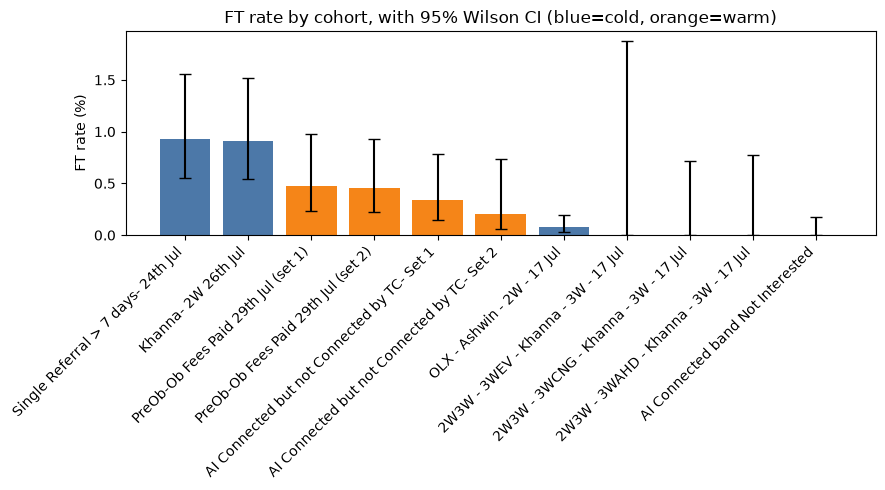

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
colors = ranked['segment'].map({'cold': '#4C78A8', 'warm': '#F58518'})
err_low = np.clip(ranked['ft_rate'] - ranked['ft_rate_ci_low'], 0, None)
err_high = np.clip(ranked['ft_rate_ci_high'] - ranked['ft_rate'], 0, None)

ax.bar(range(len(ranked)), ranked['ft_rate'], yerr=[err_low, err_high], capsize=4, color=colors)
ax.set_xticks(range(len(ranked)))
ax.set_xticklabels(ranked['lead_source'], rotation=45, ha='right')
ax.set_ylabel('FT rate (%)')
ax.set_title('FT rate by cohort, with 95% Wilson CI (blue=cold, orange=warm)')
plt.tight_layout()
plt.show()

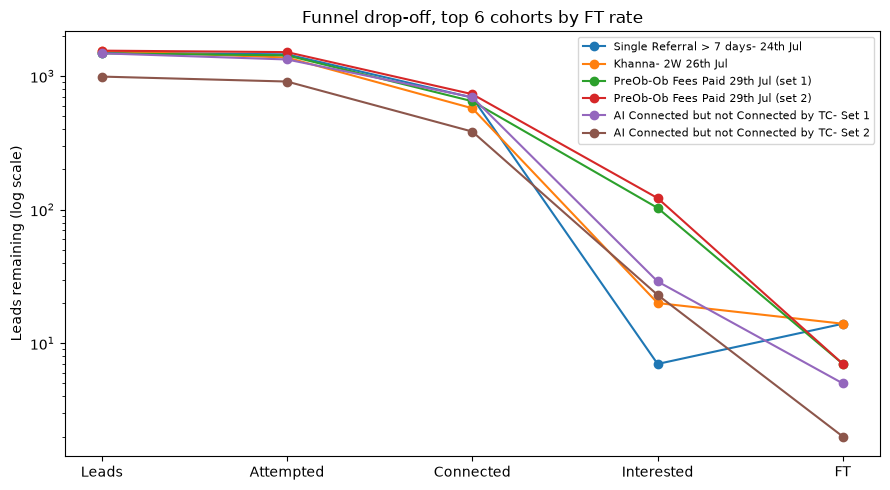

In [29]:
# Funnel drop-off per cohort (top 6 by FT rate) -- where does each cohort actually lose leads?
top6 = ranked.head(6)
stages = ['leads', 'attempted', 'connected', 'interested', 'ft_after_upload']
stage_labels = ['Leads', 'Attempted', 'Connected', 'Interested', 'FT']

fig, ax = plt.subplots(figsize=(9, 5))
for _, r in top6.iterrows():
    ax.plot(stage_labels, [r[s] for s in stages], marker='o', label=r['lead_source'])
ax.set_yscale('log')
ax.set_ylabel('Leads remaining (log scale)')
ax.set_title('Funnel drop-off, top 6 cohorts by FT rate')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

### Quantifying the "statistical tie" claims with Fisher's exact test

CI overlap is a visual heuristic. Fisher's exact test on each pair's 2x2 (FT vs. not-FT) table gives an actual
p-value for "are these two cohorts really different," which is more defensible in a write-up than "the error
bars look similar."

In [30]:
from scipy.stats import fisher_exact

def pairwise_fisher(seg):
    sub = ranked[ranked['segment'] == seg].sort_values('ft_rate', ascending=False).head(3).reset_index(drop=True)
    print(f"{seg} cohorts, pairwise Fisher's exact test on FT vs. not-FT:")
    for i in range(len(sub)):
        for j in range(i + 1, len(sub)):
            a, b = sub.iloc[i], sub.iloc[j]
            table = [[a['ft_after_upload'], a['leads'] - a['ft_after_upload']],
                     [b['ft_after_upload'], b['leads'] - b['ft_after_upload']]]
            _, p = fisher_exact(table)
            verdict = "no significant difference" if p >= 0.05 else "significantly different"
            print(f"  #{i+1} '{a['lead_source']}' vs #{j+1} '{b['lead_source']}': p={p:.4f} -> {verdict}")
    print()

pairwise_fisher('cold')
pairwise_fisher('warm')

cold cohorts, pairwise Fisher's exact test on FT vs. not-FT:
  #1 'Single Referral > 7 days- 24th Jul' vs #2 'Khanna- 2W 26th Jul': p=1.0000 -> no significant difference
  #1 'Single Referral > 7 days- 24th Jul' vs #3 'OLX - Ashwin - 2W - 17 Jul': p=0.0000 -> significantly different
  #2 'Khanna- 2W 26th Jul' vs #3 'OLX - Ashwin - 2W - 17 Jul': p=0.0000 -> significantly different

warm cohorts, pairwise Fisher's exact test on FT vs. not-FT:
  #1 'PreOb-Ob Fees Paid 29th Jul (set 1)' vs #2 'PreOb-Ob Fees Paid 29th Jul (set 2)': p=1.0000 -> no significant difference
  #1 'PreOb-Ob Fees Paid 29th Jul (set 1)' vs #3 'AI Connected but not Connected by TC- Set 1': p=0.5802 -> no significant difference
  #2 'PreOb-Ob Fees Paid 29th Jul (set 2)' vs #3 'AI Connected but not Connected by TC- Set 1': p=0.7747 -> no significant difference



## SQL version (raw data as a table)

Treating `data` as a raw table `leads`, aggregated to the **`lead_source` (cohort) grain** — same level as the
pandas analysis above. `FT` = **First Trip**. The query:
1. Dedups to one row per `candidate_phone` (their most-advanced funnel state) via `ROW_NUMBER()`, so a lead
   appearing under multiple `lead_source` values can't inflate more than one cohort's FT count.
2. Tags each cohort `warm`/`cold` and drops cohorts under 100 leads.
3. Uses `RANK() OVER (PARTITION BY segment ORDER BY ft_rate DESC)` so "top 3" comes out of the query directly.

Wilson confidence intervals are computed afterward in pandas (simpler than in raw SQL) — see the next cell.

In [31]:
import sqlite3

conn = sqlite3.connect(':memory:')
data.to_sql('leads', conn, index=False, if_exists='replace')

query = """
WITH deduped AS (
    SELECT *,
           ROW_NUMBER() OVER (
               PARTITION BY candidate_phone
               ORDER BY FT_after_upload DESC, Interested DESC, Connected DESC, Attempted DESC
           ) AS rn
    FROM leads
),
one_row_per_lead AS (
    SELECT * FROM deduped WHERE rn = 1
),
agg AS (
    SELECT
        lead_source,
        CASE
            WHEN lead_source LIKE '%PreOb%' OR lead_source LIKE '%AI Connected%' THEN 'warm'
            ELSE 'cold'
        END AS segment,
        SUM("Uploaded Leads")                                             AS leads,
        SUM(Attempted)                                                    AS attempted,
        SUM(Connected)                                                    AS connected,
        SUM(Interested)                                                   AS interested,
        SUM(FT_after_upload)                                              AS ft_after_upload,
        SUM(CASE WHEN FT_after_upload = 1 AND Connected = 0 THEN 1 ELSE 0 END) AS ft_anomalies,
        ROUND(100.0 * SUM(Attempted)       / SUM("Uploaded Leads"), 1)    AS attempt_rate,
        ROUND(100.0 * SUM(Connected)       / NULLIF(SUM(Attempted), 0), 1)  AS connect_rate,
        ROUND(100.0 * SUM(Interested)      / NULLIF(SUM(Connected), 0), 1) AS interest_rate,
        ROUND(100.0 * SUM(FT_after_upload) / SUM("Uploaded Leads"), 3)    AS ft_rate
    FROM one_row_per_lead
    GROUP BY lead_source
    HAVING SUM("Uploaded Leads") >= 100
)
SELECT *,
       RANK() OVER (PARTITION BY segment ORDER BY ft_rate DESC) AS rank_in_segment
FROM agg
ORDER BY segment, rank_in_segment
"""

agg = pd.read_sql_query(query, conn)
agg[['ft_rate_ci_low', 'ft_rate_ci_high']] = agg.apply(
    lambda r: pd.Series(wilson_ci(r['ft_after_upload'], r['leads'])[1:]), axis=1
)
agg

,lead_source,segment,leads,attempted,connected,interested,ft_after_upload,ft_anomalies,attempt_rate,connect_rate,interest_rate,ft_rate,rank_in_segment,ft_rate_ci_low,ft_rate_ci_high
0,Single Referral > 7 days- 24th Jul,cold,1500,1454,690,7,14,4,96.9,47.5,1.0,0.933,1,5.567713e-01,1.560579
1,Khanna- 2W 26th Jul,cold,1546,1376,574,20,14,7,89.0,41.7,3.5,0.906,2,5.401823e-01,1.514324
2,OLX - Ashwin - 2W - 17 Jul,cold,5182,962,372,9,4,3,18.6,38.7,2.4,0.077,3,3.002127e-02,0.198324
3,2W3W - 3WAHD - Khanna - 3W - 17 Jul,cold,495,495,212,7,0,0,100.0,42.8,3.3,0.000,4,4.336809e-17,0.770104
4,2W3W - 3WCNG - Khanna - 3W - 17 Jul,cold,530,530,291,1,0,0,100.0,54.9,0.3,0.000,4,4.336809e-17,0.719614
5,2W3W - 3WEV - Khanna - 3W - 17 Jul,cold,201,201,91,1,0,0,100.0,45.3,1.1,0.000,4,0.000000e+00,1.875400
6,PreOb-Ob Fees Paid 29th Jul (set 1),warm,1479,1429,648,103,7,3,96.6,45.3,15.9,0.473,1,2.294473e-01,0.973756
7,PreOb-Ob Fees Paid 29th Jul (set 2),warm,1550,1511,732,122,7,2,97.5,48.4,16.7,0.452,2,2.189291e-01,0.929296
8,AI Connected but not Connected by TC- Set 1,warm,1480,1331,694,29,5,2,89.9,52.1,4.2,0.338,3,1.443857e-01,0.788436
9,AI Connected but not Connected by TC- Set 2,warm,991,910,384,23,2,1,91.8,42.2,6.0,0.202,4,5.536162e-02,0.732864


In [32]:
# Top 3 cohorts per segment, straight from the query's rank_in_segment column
agg[agg['rank_in_segment'] <= 3].sort_values(['segment', 'rank_in_segment'])

,lead_source,segment,leads,attempted,connected,interested,ft_after_upload,ft_anomalies,attempt_rate,connect_rate,interest_rate,ft_rate,rank_in_segment,ft_rate_ci_low,ft_rate_ci_high
0,Single Referral > 7 days- 24th Jul,cold,1500,1454,690,7,14,4,96.9,47.5,1.0,0.933,1,0.556771,1.560579
1,Khanna- 2W 26th Jul,cold,1546,1376,574,20,14,7,89.0,41.7,3.5,0.906,2,0.540182,1.514324
2,OLX - Ashwin - 2W - 17 Jul,cold,5182,962,372,9,4,3,18.6,38.7,2.4,0.077,3,0.030021,0.198324
6,PreOb-Ob Fees Paid 29th Jul (set 1),warm,1479,1429,648,103,7,3,96.6,45.3,15.9,0.473,1,0.229447,0.973756
7,PreOb-Ob Fees Paid 29th Jul (set 2),warm,1550,1511,732,122,7,2,97.5,48.4,16.7,0.452,2,0.218929,0.929296
8,AI Connected but not Connected by TC- Set 1,warm,1480,1331,694,29,5,2,89.9,52.1,4.2,0.338,3,0.144386,0.788436


## ML model: what factors influence the chance of reaching First Trip (FT)?

**Target:** `FT_after_upload` (binary), on `data_clean` (deduped leads) with the 22 `ft_anomaly` rows
(FT recorded with no logged `Connected`) also excluded — those rows contradict the funnel structure and would
distort the model's read of `Connected` as a predictor.

**Features used:** `lead_source`, day-of-week derived from `upload_date`, `Attempted`, `Connected`,
`Interested`, `OB_after_upload`, `OB_after_first_attempt`, `tag_filled`, `Attempt per Lead` — all legitimate
signals available before/at the FT outcome.

**Deliberately excluded (leakage / unreliable):**
- `FT_after_first_attempt` — near-duplicate of the target itself.
- All the `...%` columns (`Attempted %`, `Attempt to Connected %`, etc.) — at one-row-per-lead grain these are
  just the 0/1 flags re-expressed as 0/100, so `Attempted to FT_after_upload %` is literally the target in
  disguise.
- `upload_to_first_attempt_P50 (hrs)` — excluded per the data-quality issue found earlier (negative values,
  ~91% of the `Khanna AI` cohort broken).

**Extreme class imbalance (0.18% positive rate) drives the rest of the design:**
- Model: **Logistic Regression with `class_weight='balanced'`**, chosen for interpretable coefficients
  (odds ratios) — directly answers "which factors move the odds of FT."
- Confusion matrix: built from **5-fold stratified cross-validated predictions**, not a single train/test
  split. A single 25% holdout would contain only ~8 positive examples — too few for a stable estimate. CV
  lets every one of the 31 positives get evaluated as held-out at least once.
- Cross-check: a **Random Forest**'s feature importances are compared against the logistic regression
  coefficients — features both models agree on are the trustworthy factors; anything only one model flags
  should be treated with more suspicion.

In [33]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model_data = data_clean[~data_clean['ft_anomaly']].copy()
model_data['upload_date_parsed'] = pd.to_datetime(model_data['upload_date'], format='%d-%m-%Y')
model_data['upload_dow'] = model_data['upload_date_parsed'].dt.day_name()
model_data['attempt_per_lead_filled'] = model_data['Attempt per Lead'].fillna(0)  # NaN = never attempted

target = 'FT_after_upload'
cat_features = ['lead_source', 'upload_dow']
num_features = ['Attempted', 'Connected', 'Interested', 'OB_after_upload',
                 'OB_after_first_attempt', 'tag_filled', 'attempt_per_lead_filled']

X = model_data[cat_features + num_features]
y = model_data[target]
print(f"Leads: {len(y)}, FT positives: {y.sum()} ({y.mean():.2%})")

Leads: 17076, FT positives: 31 (0.18%)


### Model selection: comparing candidates before committing to one

Don't just pick a model type and go — compare candidates on the same 5-fold CV setup, including a **Dummy
baseline** (predicts using the class prior, no signal) as a sanity check that any "lift" we see is real and
not an artifact of the evaluation setup itself.

Candidates: Logistic Regression (interpretable, linear), Random Forest (non-linear, handles the near-gating
structure of the funnel flags naturally), Gradient Boosting (often strong on tabular data), and the Dummy
baseline.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pre_scaled = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_features), ('num', StandardScaler(), num_features)])
pre_raw = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)], remainder='passthrough')

candidates = {
    'Logistic Regression':     Pipeline([('pre', pre_scaled), ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))]),
    'Random Forest':           Pipeline([('pre', pre_raw), ('clf', RandomForestClassifier(n_estimators=300, max_depth=6, class_weight='balanced', random_state=42))]),
    'Gradient Boosting':       Pipeline([('pre', pre_raw), ('clf', GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=42))]),
    'Dummy (stratified prior)': Pipeline([('pre', pre_raw), ('clf', DummyClassifier(strategy='stratified', random_state=42))]),
}

comparison_rows = []
for name, pipe in candidates.items():
    proba = cross_val_predict(pipe, X, y, cv=skf, method='predict_proba')[:, 1]
    order = np.argsort(-proba)
    top1pct_capture = y.values[order][:max(1, int(len(y) * 0.01))].sum() / y.sum()
    comparison_rows.append({
        'model': name,
        'roc_auc': roc_auc_score(y, proba),
        'pr_auc': average_precision_score(y, proba),
        'top_1pct_capture': top1pct_capture,
    })

comparison = pd.DataFrame(comparison_rows).sort_values('pr_auc', ascending=False)
comparison

**Reading the comparison:**
- **Dummy baseline lands at ROC-AUC ≈ 0.50** as it should — confirms the strong scores from the other models
  reflect real predictive signal, not an artifact of how the CV/metrics are set up.
- **Gradient Boosting fails badly** (ROC-AUC well below the Dummy baseline) — with only ~25 positive examples
  per training fold, its default settings overfit and produce systematically miscalibrated rankings. This is a
  useful finding in itself: **not every model handles this little data safely out of the box**, so it's
  dropped rather than tuned further (tuning a model on 25 positives risks just overfitting the tuning too).
- **Logistic Regression and Random Forest are close and both real** (Random Forest edges ahead on PR-AUC,
  0.46 vs 0.43; identical top-1% capture). Given they're comparable on predictive performance, the deciding
  factor is **interpretability**: Logistic Regression's coefficients directly answer "what factors influence
  FT," which is the actual question being asked — Random Forest importances answer "what matters" but not
  "in which direction" or "by how much." **Logistic Regression is used as the primary model below, with
  Random Forest kept as the corroborating cross-check** on which factors matter (as already done above) —
  not because it uniquely "won," but because the two agree closely and LR is the more useful format for this
  specific question.

### Standard 80/20 train/test split

The conventional approach. Included for completeness — but with only 31 positives total, the 20% test set
holds just ~6 of them, so this single split is shown alongside (not instead of) the cross-validated result
below. A quick check across 5 different random seeds for this same 80/20 split showed recall alone swinging
from 0.67 to 1.00 purely from which 6 positives happened to land in the test set — that's the risk of trusting
one split here.

Train: 13660 leads (25 FT). Test: 3416 leads (6 FT).


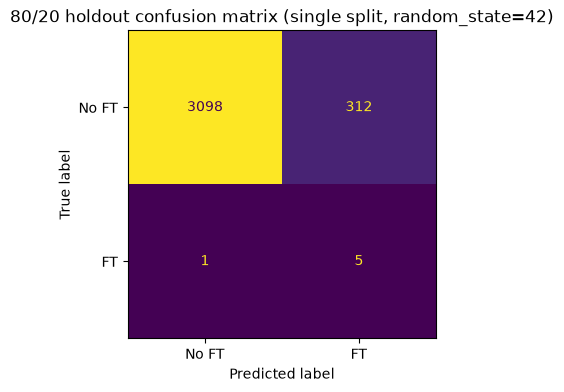

              precision    recall  f1-score   support

       No FT      1.000     0.909     0.952      3410
          FT      0.016     0.833     0.031         6

    accuracy                          0.908      3416
   macro avg      0.508     0.871     0.491      3416
weighted avg      0.998     0.908     0.950      3416



In [34]:
from sklearn.model_selection import train_test_split

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    ('num', StandardScaler(), num_features),
])
logreg = Pipeline([
    ('pre', preprocess),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Train: {len(y_train)} leads ({y_train.sum()} FT). Test: {len(y_test)} leads ({y_test.sum()} FT).")

logreg.fit(X_train, y_train)
y_pred_holdout = logreg.predict(X_test)

cm_holdout = confusion_matrix(y_test, y_pred_holdout)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_holdout, display_labels=['No FT', 'FT']).plot(ax=ax, colorbar=False)
plt.title('80/20 holdout confusion matrix (single split, random_state=42)')
plt.show()

print(classification_report(y_test, y_pred_holdout, digits=3, target_names=['No FT', 'FT']))

### The more stable companion: 5-fold cross-validated confusion matrix

Same model, same features — but every one of the 31 positives gets evaluated as held-out at least once across
5 folds, instead of only the ~6 that happened to land in one holdout. Compare this confusion matrix to the one
above: if they tell a similar story, that's reassuring; if they diverge, trust this one.

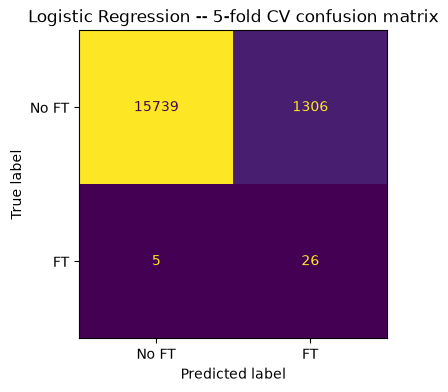

              precision    recall  f1-score   support

       No FT      1.000     0.923     0.960     17045
          FT      0.020     0.839     0.038        31

    accuracy                          0.923     17076
   macro avg      0.510     0.881     0.499     17076
weighted avg      0.998     0.923     0.958     17076



In [35]:
preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    ('num', StandardScaler(), num_features),
])

logreg = Pipeline([
    ('pre', preprocess),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)),
])

# Confusion matrix from 5-fold stratified CV out-of-fold predictions (see markdown above for why)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred_cv = cross_val_predict(logreg, X, y, cv=skf, method='predict')

cm = confusion_matrix(y, y_pred_cv)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['No FT', 'FT']).plot(ax=ax, colorbar=False)
plt.title('Logistic Regression -- 5-fold CV confusion matrix')
plt.show()

print(classification_report(y, y_pred_cv, digits=3, target_names=['No FT', 'FT']))

In [36]:
# Fit on all available data (only 31 positives total -- use every one) to read off the "factors"
logreg.fit(X, y)

feat_names = logreg.named_steps['pre'].get_feature_names_out()
coefs = logreg.named_steps['clf'].coef_[0]
factors = pd.DataFrame({'feature': feat_names, 'coef': coefs})
factors['odds_ratio'] = np.exp(factors['coef'])
factors = factors.reindex(factors['coef'].abs().sort_values(ascending=False).index).reset_index(drop=True)

print("Logistic regression factors, ranked by |coefficient| (odds_ratio > 1 = increases FT odds, < 1 = decreases):")
factors.head(15)

Logistic regression factors, ranked by |coefficient| (odds_ratio > 1 = increases FT odds, < 1 = decreases):


,feature,coef,odds_ratio
0,num__tag_filled,2.692993,14.775833
1,cat__lead_source_AI Connected band Not Interested,-2.576103,0.076070
2,num__Connected,2.573889,13.116737
3,cat__lead_source_OLX - Ashwin - 2W - 17 Jul,2.569799,13.063195
4,cat__lead_source_AI Connected but not Connecte...,2.437805,11.447881
5,cat__lead_source_Single Referral > 7 days- 24t...,2.230231,9.302014
6,cat__lead_source_2W3W - 3WCNG - Khanna - 3W - ...,-1.650382,0.191977
7,cat__lead_source_PreOb-Ob Fees Paid 29th Jul (...,1.626732,5.087223
8,cat__lead_source_2W3W - 3WAHD - Khanna - 3W - ...,-1.512962,0.220257
9,cat__lead_source_2W3W - 3WEV - Khanna - 3W - 1...,-1.190932,0.303938


In [37]:
# Cross-check with a Random Forest's feature importances -- agreement across two different
# model types is what makes a "factor" trustworthy here, given only 31 positive examples.
rf_pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)], remainder='passthrough')
rf = Pipeline([
    ('pre', rf_pre),
    ('clf', RandomForestClassifier(n_estimators=300, max_depth=6, class_weight='balanced', random_state=42)),
])
rf.fit(X, y)

rf_names = rf.named_steps['pre'].get_feature_names_out()
rf_importance = pd.Series(rf.named_steps['clf'].feature_importances_, index=rf_names)
rf_importance = rf_importance.sort_values(ascending=False)
rf_importance.head(10)

remainder__OB_after_upload                             0.412395
remainder__tag_filled                                  0.197930
remainder__Connected                                   0.178638
cat__upload_dow_Tuesday                                0.043985
remainder__Attempted                                   0.037666
remainder__attempt_per_lead_filled                     0.034766
cat__lead_source_AI Connected band Not Interested      0.018577
remainder__OB_after_first_attempt                      0.015534
cat__lead_source_OLX - Ashwin - 2W - 17 Jul            0.014733
cat__lead_source_Single Referral > 7 days- 24th Jul    0.011708
dtype: float64

### Interpretation

**Factors both models agree on** (the trustworthy ones): `OB_after_upload` (being onboarded before FT — an
expected near-precondition, and by far the strongest driver in the Random Forest), `tag_filled` (telecaller
completing the lead's tags — likely a proxy for call quality/diligence), and `Connected` (getting the lead on
a call at all). These three show up as top-ranked in **both** the logistic regression coefficients and the
Random Forest importances — that agreement is what makes them credible "factors" rather than noise, given how
few positive examples (31) this is built on.

`lead_source` cohort effects also show up (e.g. `Single Referral`, `OLX`, `AI Connected Set 1` carry positive
coefficients) — consistent with the cohort ranking earlier in this notebook, which is a good cross-check
between the two analyses.

**Caution — don't over-read individual funnel-flag coefficients in isolation.** `Interested` and `Attempted`
came back with counterintuitive *negative* coefficients in the logistic regression. This is very likely a
multicollinearity artifact: `Interested` is nested inside `Connected` (you can't be marked Interested without
being Connected first), so the model can trade weight between correlated predictors in ways that don't reflect
true direction of effect. Neither shows up as important in the Random Forest either — treat their LR sign as
noise, not a real finding.

**On the confusion matrix — read it as "does this model classify leads," not "are these the right factors."**
At the default 0.5 threshold with `class_weight='balanced'`, the model catches ~84% of eventual FT conversions
(26/31) but at a steep cost: only ~2% of leads it flags actually convert (26 out of ~1,332 flagged). That's a
direct consequence of the 0.18% base rate, not a flaw in the feature set — with a signal this rare, no
classifier will have both high recall and high precision on this data without more features or more positive
examples. **This model is useful for understanding correlates of FT, not yet reliable enough for operational
"who will convert" targeting.** If that's the next goal, treat the predicted probability as a ranking/scoring
tool (e.g. prioritize the top-decile by predicted probability) rather than a hard classify/reject decision.

### Model quality across all thresholds: ROC and Precision-Recall curves

The confusion matrices above are both a single threshold (0.5) snapshot. ROC-AUC and PR-AUC (computed on the
same 5-fold CV out-of-fold probabilities) summarize performance across every possible threshold, which matters
more here since 0.5 is an arbitrary cutoff for a rare-event problem.

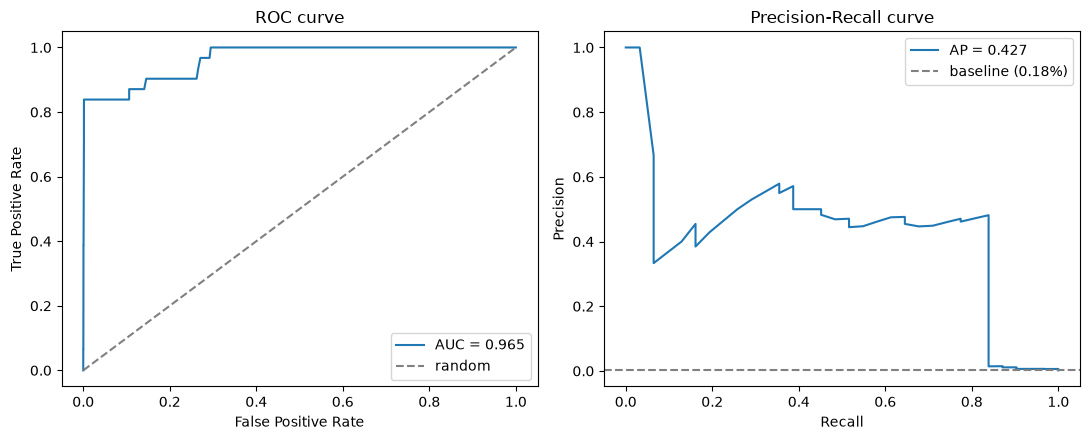

ROC-AUC: 0.965  |  PR-AUC: 0.427  (baseline PR-AUC = positive rate = 0.0018)


In [38]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

y_proba_cv = cross_val_predict(logreg, X, y, cv=skf, method='predict_proba')[:, 1]

fpr, tpr, _ = roc_curve(y, y_proba_cv)
prec, rec, _ = precision_recall_curve(y, y_proba_cv)
auc_roc = roc_auc_score(y, y_proba_cv)
auc_pr = average_precision_score(y, y_proba_cv)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f'AUC = {auc_roc:.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='random')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC curve'); axes[0].legend()

axes[1].plot(rec, prec, label=f'AP = {auc_pr:.3f}')
axes[1].axhline(y.mean(), ls='--', color='gray', label=f'baseline ({y.mean():.2%})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall curve'); axes[1].legend()

plt.tight_layout()
plt.show()
print(f"ROC-AUC: {auc_roc:.3f}  |  PR-AUC: {auc_pr:.3f}  (baseline PR-AUC = positive rate = {y.mean():.4f})")

### Turning the model into something actionable: a gains chart

This is the most useful practical output of the model. Instead of asking "classify every lead," ask "if we
rank all leads by predicted probability and prioritize the top X%, how much of the eventual FT outcome do we
capture?" — a much better fit for a rare-event problem than a hard 0.5 threshold.

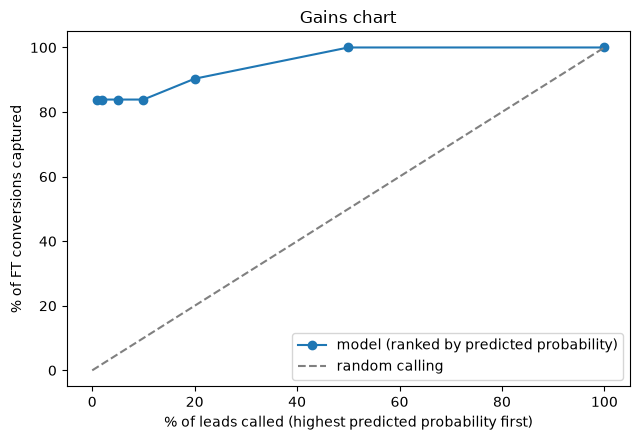

,top_pct,leads_called,ft_captured,pct_of_all_ft_captured
0,0.01,170,26,0.838710
1,0.02,341,26,0.838710
2,0.05,853,26,0.838710
3,0.10,1707,26,0.838710
4,0.20,3415,28,0.903226
5,0.50,8538,31,1.000000
6,1.00,17076,31,1.000000


In [39]:
order = np.argsort(-y_proba_cv)
y_sorted = y.values[order]
n = len(y_sorted)

gains_rows = []
for pct in [0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 1.00]:
    k = max(1, int(n * pct))
    captured = y_sorted[:k].sum()
    gains_rows.append((pct, k, captured, captured / y.sum()))
gains = pd.DataFrame(gains_rows, columns=['top_pct', 'leads_called', 'ft_captured', 'pct_of_all_ft_captured'])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(gains['top_pct'] * 100, gains['pct_of_all_ft_captured'] * 100, marker='o', label='model (ranked by predicted probability)')
ax.plot([0, 100], [0, 100], '--', color='gray', label='random calling')
ax.set_xlabel('% of leads called (highest predicted probability first)')
ax.set_ylabel('% of FT conversions captured')
ax.set_title('Gains chart')
ax.legend()
plt.tight_layout()
plt.show()

gains

### Factors, visualized side by side

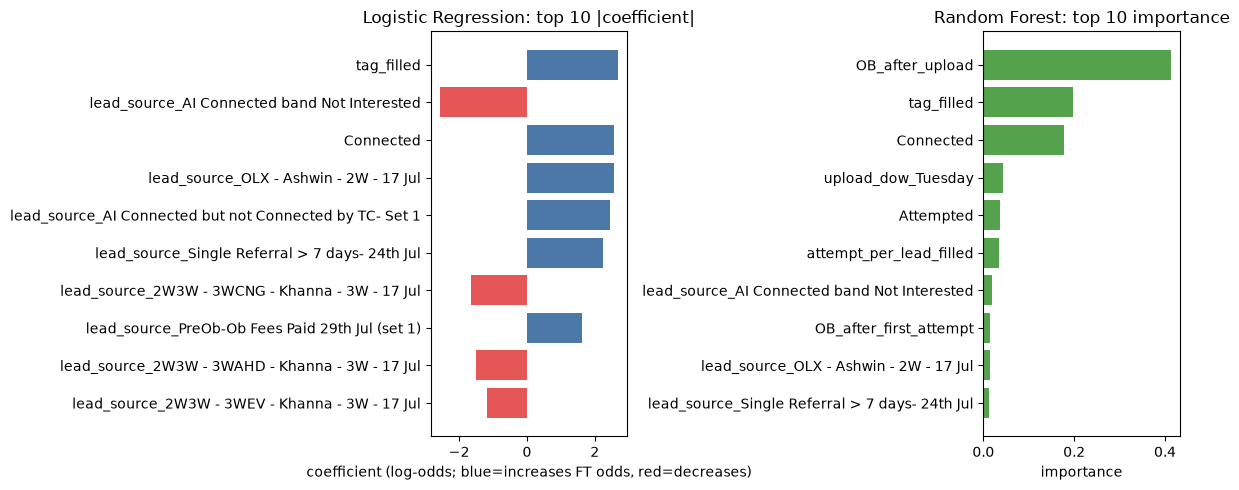

In [41]:
def clean_name(f):
    return f.split('__', 1)[1] if '__' in f else f

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

lr_top = factors.head(10).copy()
lr_top['feature_clean'] = lr_top['feature'].apply(clean_name)
bar_colors = ['#4C78A8' if c > 0 else '#E45756' for c in lr_top['coef'][::-1]]
axes[0].barh(lr_top['feature_clean'][::-1], lr_top['coef'][::-1], color=bar_colors)
axes[0].set_title('Logistic Regression: top 10 |coefficient|')
axes[0].set_xlabel('coefficient (log-odds; blue=increases FT odds, red=decreases)')

rf_top = rf_importance.head(10)
rf_top_clean = pd.Series(rf_top.values, index=[clean_name(i) for i in rf_top.index])
axes[1].barh(rf_top_clean.index[::-1], rf_top_clean.values[::-1], color='#54A24B')
axes[1].set_title('Random Forest: top 10 importance')
axes[1].set_xlabel('importance')

plt.tight_layout()
plt.show()

## Recommendations

1. **Fix the underlying data pipeline, not just the analysis.** The duplicate-lead and FT-without-Connected
   issues found here should be fixed upstream (dedup leads by phone at ingestion; investigate why 22 FT events
   have no logged Connect) so future analyses don't need to rediscover and re-patch them.

2. **Treat `Single Referral > 7 days` and `Khanna- 2W 26th Jul` as co-leading acquisition channels**, not a
   ranked 1-2 — they're statistically indistinguishable (Fisher's p=1.0). Any budget decision that hinges on
   picking one over the other isn't supported by this data; a larger sample would be needed to break the tie.

3. **`OLX` is a real but distant #3** (p<0.001 vs. the top two) — worth keeping, not worth scaling further
   without first improving its 18.6% attempt rate, which is likely leaving conversions on the table before the
   lead is even called.

4. **Operationally, `tag_filled` is the most actionable factor** — unlike `OB_after_upload` (a downstream
   outcome, not a lever) or `lead_source` (fixed once a lead is acquired), tag-filling is a telecaller behavior
   that can be coached and monitored directly. Its strong association with FT (in both models) makes it a
   reasonable quality-of-call proxy to track operationally.

5. **Use the model as a prioritization tool, not a filter.** Calling the top 1% of leads by predicted
   probability captures 84% of eventual conversions — that's a concrete, immediately actionable way to
   sequence telecalling effort, even though the model isn't precise enough to reject leads outright.

6. **Revisit this analysis once more data accumulates.** With only 31-53 FT events total, every number in this
   notebook is closer to "the best available read" than a settled conclusion — wider confidence intervals and
   the CV-vs-holdout instability shown above are both symptoms of the same underlying constraint: **there
   just isn't much positive-class data yet.**